In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


using print (df.info()) to print data
use print(f'Total rows: {len(df)}") to count all the rows
use print(f"total track IDs: {df['track_id'].nunique()})  to check for duplicate track ids

PUrpose: Inspect data intergrity and strcuture


In [10]:
df = pd.read_csv("spotify.csv")
df.info()
print(f"Total rows: {len(df):,}")
print(f"Unique track IDs: {df['track_id'].nunique():,}")
print(f"Repeated track ID rows: {df['track_id'].duplicated().sum():,}")
print(f"Fully duplicated rows: {df.duplicated().sum()}")


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

89,741 unique tracks out of 114,000 rows, so 24,259 rows are repeats. One row is missing artist, album and track name

In [11]:
# The one row with missing values
print(df[df.isna().any(axis=1)])

# Most repeated track IDs, and why they repeat
print(df['track_id'].value_counts().head(5))
top_id = df['track_id'].value_counts().index[0]
df[df['track_id'] == top_id][['track_name', 'artists', 'popularity', 'track_genre']]

       Unnamed: 0                track_id artists album_name track_name  \
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN   

       popularity  duration_ms  explicit  danceability  energy  ...  loudness  \
65900           0            0     False         0.501   0.583  ...     -9.46   

       mode  speechiness  acousticness  instrumentalness  liveness  valence  \
65900     0       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature  track_genre  
65900  138.391               4        k-pop  

[1 rows x 21 columns]
track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2kkvB3RNRzwjFdGhaUA0tz    8
2Ey6v4Sekh3Z0RUSISRosD    8
2vU6bm5hVF2idVknGzqyPL    7
4GPQDyw9hC1DiZVh0ouDVL    7
Name: count, dtype: int64


,track_name,artists,popularity,track_genre
8315,Baby Blue - Remastered 2010,Badfinger,67,blues
19759,Baby Blue - Remastered 2010,Badfinger,67,country
34728,Baby Blue - Remastered 2010,Badfinger,67,folk
62226,Baby Blue - Remastered 2010,Badfinger,67,j-pop
63087,Baby Blue - Remastered 2010,Badfinger,67,j-rock
82064,Baby Blue - Remastered 2010,Badfinger,67,power-pop
84129,Baby Blue - Remastered 2010,Badfinger,67,psych-rock
99727,Baby Blue - Remastered 2010,Badfinger,67,singer-songwriter
102732,Baby Blue - Remastered 2010,Badfinger,67,songwriter


(df[df['artists'].isna()]) give us  which track is doesnt have an artist name , there is one .Interstingly , there is still some Vaule to it  , like eneergy or genere 
(df['track_id'].value_counts().head(5)) print out 5 most duplicated track_id , this help because it  help us move on to the next step which is aggregating the repeated tracks into single ovservation unit.


In [12]:
print("Rows, columns:", df.shape)
print("Unique tracks:", df['track_id'].nunique())
print("Unique artists:", df['artists'].nunique())
print("Unique genres:", df['track_genre'].nunique())
print("Rows per genre (min, max):", df['track_genre'].value_counts().min(), df['track_genre'].value_counts().max())
df.head()

Rows, columns: (114000, 21)
Unique tracks: 89741
Unique artists: 31437
Unique genres: 114
Rows per genre (min, max): 1000 1000


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [13]:
# Drop the leftover index column
df = df.drop(columns=['Unnamed: 0'])

# Drop the single row with no artist, album, or track name
df = df.dropna(subset=['artists', 'album_name', 'track_name'])
print(df.shape)

# Suspicious zeros
print("duration_ms == 0:", (df['duration_ms'] == 0).sum())
print("tempo == 0:", (df['tempo'] == 0).sum())
print("popularity == 0:", (df['popularity'] == 0).sum())


(113999, 20)
duration_ms == 0: 0
tempo == 0: 157
popularity == 0: 16019


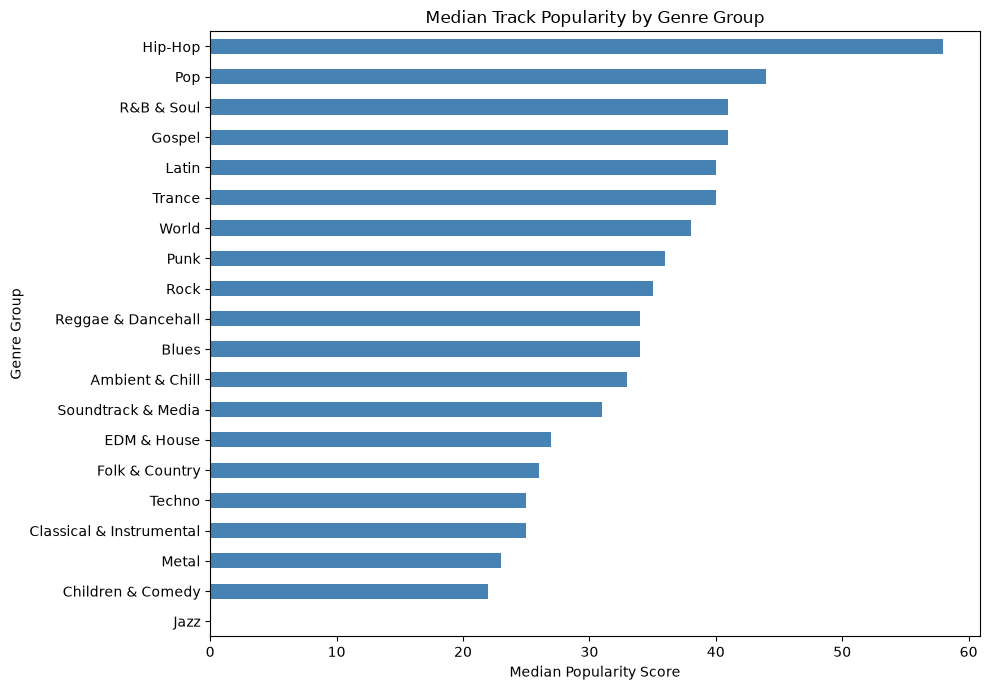

In [25]:
# One row per track per genre group, so a song tagged rock + alt-rock counts once in Rock
by_group = df.drop_duplicates(subset=['track_id', 'genre_group'])
median_pop = by_group.groupby('genre_group')['popularity'].median().sort_values()
plt.figure(figsize=(10, 7))
median_pop.plot(kind='barh', color='steelblue')
plt.title('Median Track Popularity by Genre Group')
plt.xlabel('Median Popularity Score')
plt.ylabel('Genre Group')
plt.tight_layout()
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18876\655430146.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='genre_group', y='popularity', data=by_group, palette='Set2', showfliers=False)


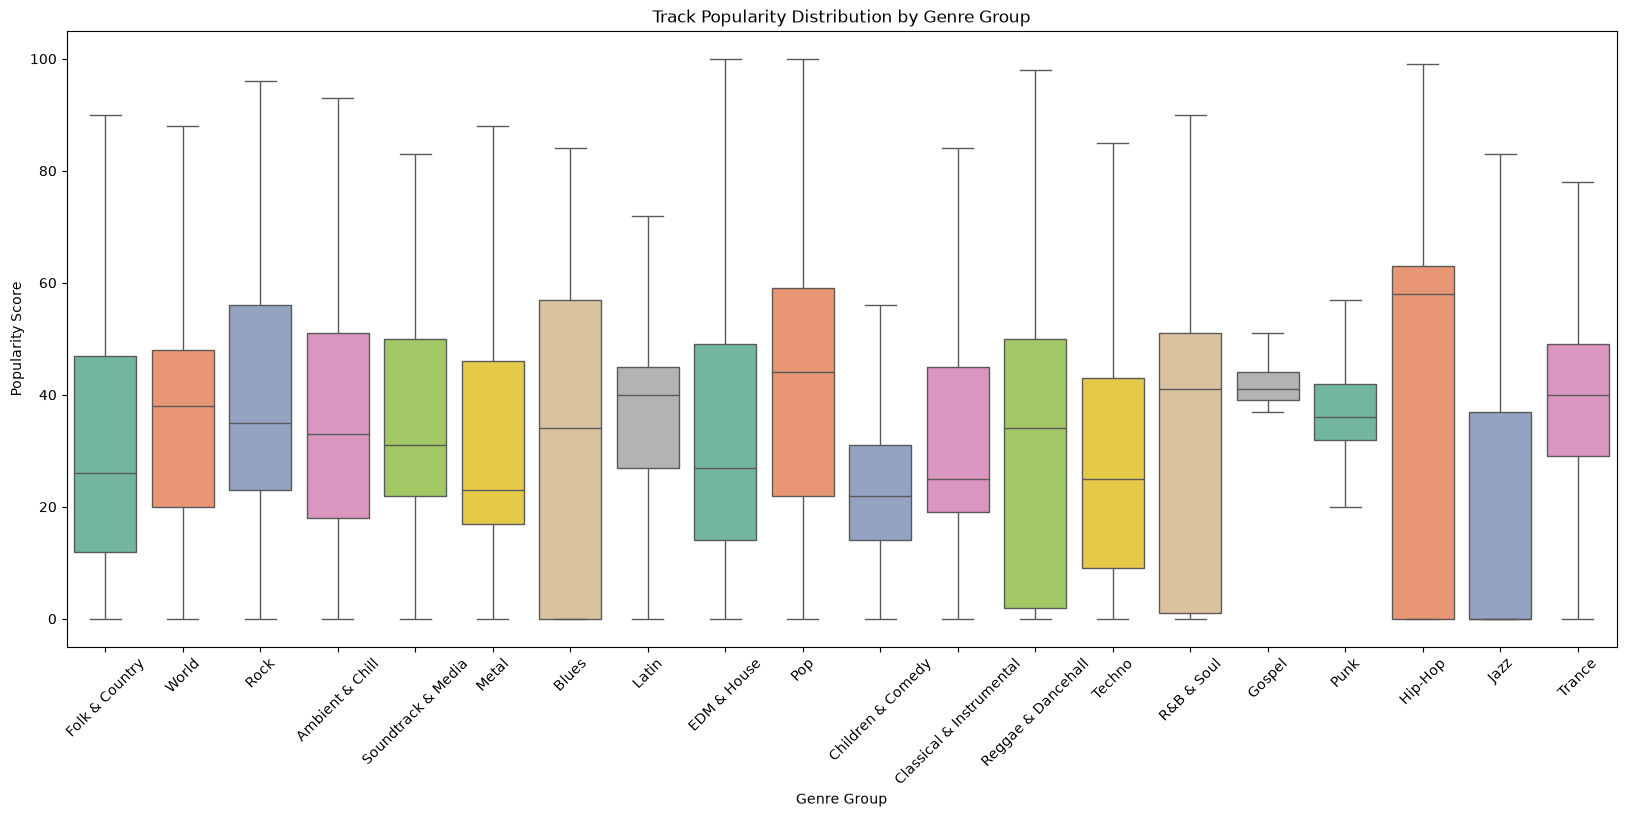

In [33]:
by_group = df.drop_duplicates(subset=['track_id', 'genre_group'])
plt.figure(figsize=(20, 8))
sns.boxplot(x='genre_group', y='popularity', data=by_group, palette='Set2', showfliers=False)
plt.title('Track Popularity Distribution by Genre Group')
plt.xlabel('Genre Group')   
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)     
plt.show()

_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________
                                                                                              CUT OFF HERE

In [14]:
from numpy import mean
df_unique = df.groupby(by=['track_id', 'artists', 'album_name', 'track_name'], as_index=False).agg({
    'popularity': 'mean',
    'duration_ms': 'first',
    'danceability': 'mean',
    'energy': 'mean',
    'loudness': 'mean',
    'valence': 'mean',
    'acousticness': 'mean',
    'tempo': 'mean',
    'explicit': 'first',
    'speechiness': 'mean',
    'instrumentalness': 'mean',
    'liveness': 'mean',
    'track_genre': lambda genres: ', '.join(sorted(genres.dropna().unique()))})

print(df_unique.shape)
print(df_unique['track_id'].nunique())
print(df_unique.head(10))

(89740, 17)
89740
                 track_id                   artists                album_name  \
0  0000vdREvCVMxbQTkS888c                      Rill                     Lolly   
1  000CC8EParg64OmTxVnZ0p                 Glee Cast           Glee Love Songs   
2  000Iz0K615UepwSJ5z2RE5  Paul Kalkbrenner;Pig&Dan                         X   
3  000RDCYioLteXcutOjeweY             Jordan Sandhu                Teeje Week   
4  000qpdoc97IMTBvF8gwcpy          Paul Kalkbrenner                      Zeit   
5  0017XiMkqbTfF2AUOzlhj6              Chad Daniels        Busy Being Awesome   
6  001APMDOl3qtx1526T11n1         Pink Sweat$;Kirby                   New RnB   
7  001YQlnDSduXd5LgBd66gT               Soda Stereo  Soda Stereo (Remastered)   
8  001pyq8FLNSL1C8orNLI0b    Old Crow Medicine Show                  O.C.M.S.   
9  002qpSULhHAw6DGqFxbaO1        Tokyo Ghetto Pussy                Disco 2001   

                                          track_name  popularity  duration_ms  \
0        

Codes above help filter out duplicated song , groupby help definets what make a row unqie , merges same items .
Use lamba to deduplicates genres ,build a a list string (text - str) - also dont have to use def
Metrics with inst 64 , float 64 is calc using mean to give cloest vaule and reduce variances
metric with bool (true false) use first , there is only one entries for each row.
print

In [15]:
def get_df_unique():
    return df.groupby(by=['track_id', 'artists', 'album_name', 'track_name'], as_index=False).agg({
        'popularity': 'mean',
        'duration_ms': 'first',
        'danceability': 'mean',
        'energy': 'mean',
        'loudness': 'mean',
        'speechiness': 'mean',
        'acousticness': 'mean',
        'instrumentalness': 'mean',
        'liveness': 'mean',
        'valence': 'mean',
        'tempo': 'mean',
        'explicit': 'first',
        'track_genre': lambda genres: ', '.join(sorted(genres.dropna().unique()))
    })


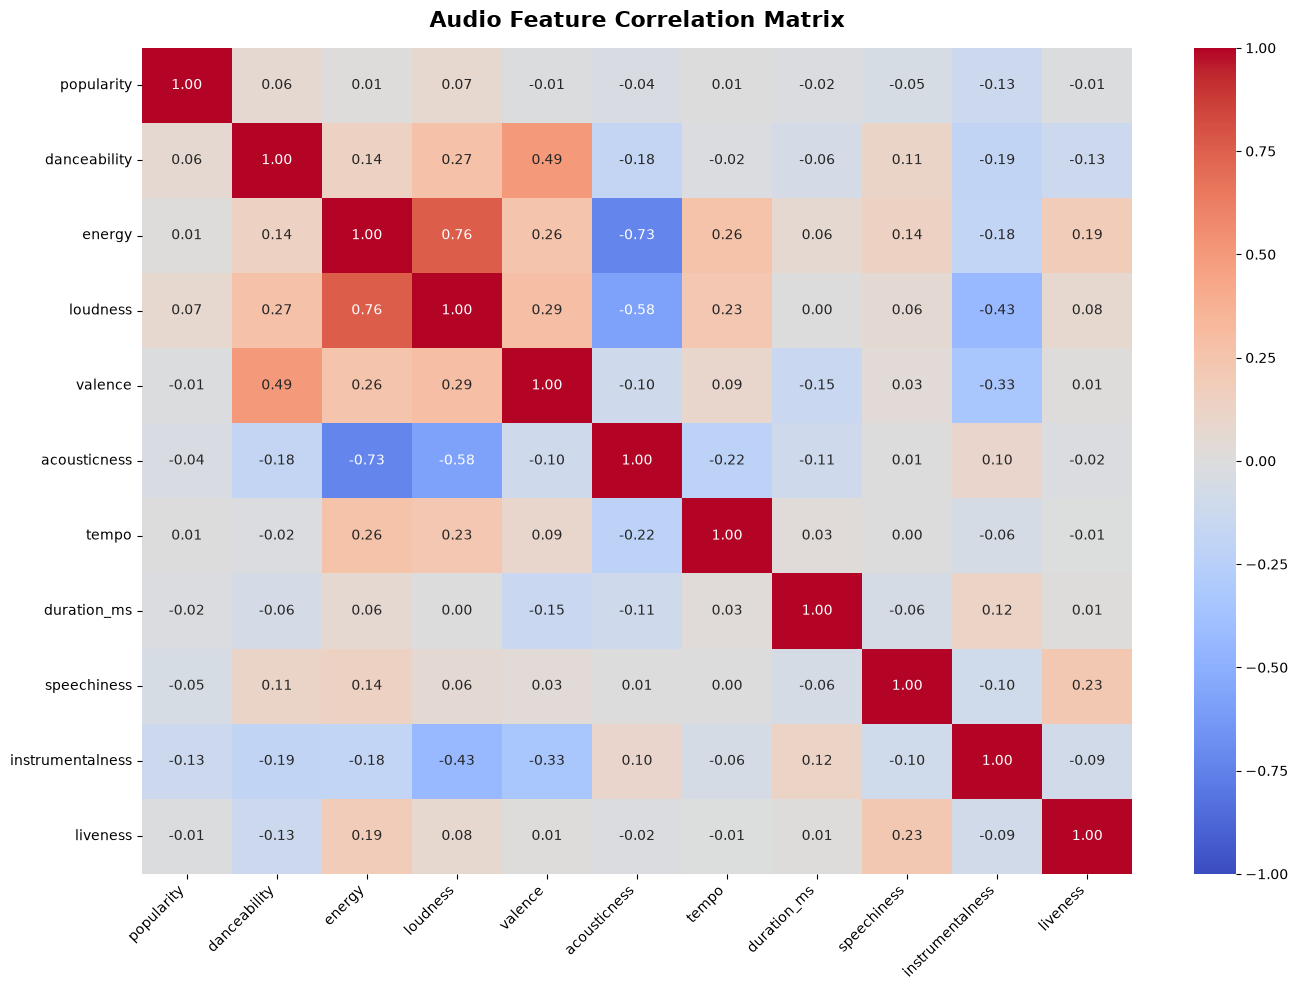

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_corr = [
    'popularity', 'danceability', 'energy', 'loudness', 'valence',
    'acousticness', 'tempo', 'duration_ms', 'speechiness',
    'instrumentalness', 'liveness'
]

corr_matrix = df_unique[numeric_corr].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Audio Feature Correlation Matrix", fontdict={'fontsize': 16, 'fontweight': 'bold'}, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
numeric_corr = ['popularity', 'danceability', 'energy', 'loudness', 'valence', 'acousticness', 'tempo', 'duration_ms' , 'speechiness' , 'instrumentalness', 'liveness', ]



In [17]:
df_unique.columns

Index(['track_id', 'artists', 'album_name', 'track_name', 'popularity',
       'duration_ms', 'danceability', 'energy', 'loudness', 'valence',
       'acousticness', 'tempo', 'explicit', 'speechiness', 'instrumentalness',
       'liveness', 'track_genre'],
      dtype='str')

In [18]:
from collections import Counter
import pandas as pd

top_20 = df_unique.sort_values(by='popularity', ascending=False).head(20)
print("=== TOP 20 MOST POPULAR TRACKS ===")
print(top_20[['track_name', 'artists', 'popularity', 'track_genre']].to_string(index=False))
top_100 = df_unique.sort_values(by='popularity', ascending=False).head(100)
genre_counts = Counter()

for genres_str in top_100['track_genre'].dropna():
    for g in genres_str.split(', '):
        genre_counts[g] += 1

top_genres_series = pd.Series(genre_counts).sort_values(ascending=False).head(10)

print("\n=== MOST FREQUENT GENRES IN THE TOP 100 TRACKS ===")
print(top_genres_series)


=== TOP 20 MOST POPULAR TRACKS ===
                           track_name                    artists  popularity                      track_genre
            Unholy (feat. Kim Petras)       Sam Smith;Kim Petras       100.0                       dance, pop
Quevedo: Bzrp Music Sessions, Vol. 52           Bizarrap;Quevedo        99.0                          hip-hop
                           La Bachata              Manuel Turizo        98.0 latin, latino, reggae, reggaeton
                      I'm Good (Blue)    David Guetta;Bebe Rexha        98.0                  dance, edm, pop
                      Me Porto Bonito Bad Bunny;Chencho Corleone        97.0 latin, latino, reggae, reggaeton
                     Tití Me Preguntó                  Bad Bunny        97.0 latin, latino, reggae, reggaeton
                      I Ain't Worried                OneRepublic        96.0                 piano, pop, rock
                  Under The Influence                Chris Brown        96.0         

In [19]:
genres = sorted(df['track_genre'].unique())
print(len(genres))
print(genres)

114
['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass', 'blues', 'brazil', 'breakbeat', 'british', 'cantopop', 'chicago-house', 'children', 'chill', 'classical', 'club', 'comedy', 'country', 'dance', 'dancehall', 'death-metal', 'deep-house', 'detroit-techno', 'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep', 'edm', 'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk', 'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove', 'grunge', 'guitar', 'happy', 'hard-rock', 'hardcore', 'hardstyle', 'heavy-metal', 'hip-hop', 'honky-tonk', 'house', 'idm', 'indian', 'indie', 'indie-pop', 'industrial', 'iranian', 'j-dance', 'j-idol', 'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino', 'malay', 'mandopop', 'metal', 'metalcore', 'minimal-techno', 'mpb', 'new-age', 'opera', 'pagode', 'party', 'piano', 'pop', 'pop-film', 'power-pop', 'progressive-house', 'psych-rock', 'punk', 'punk-rock', 'r-n-b', 'reggae', 'reggaeton', 'ro

In [20]:
synonym_map = {
    # Rock & Alternative
    'alt-rock': 'Rock',
    'alternative': 'Rock',
    'hard-rock': 'Rock',
    'grunge': 'Rock',
    'psych-rock': 'Rock',
    'rock': 'Rock',
    'rock-n-roll': 'Rock',
    'rockabilly': 'Rock',
    'j-rock': 'Rock',
    'goth': 'Rock',
    'industrial': 'Rock',
    'emo': 'Rock',
    # Metal
    'black-metal': 'Metal',
    'death-metal': 'Metal',
    'heavy-metal': 'Metal',
    'metal': 'Metal',
    'metalcore': 'Metal',
    'grindcore': 'Metal',
    # Pop & Sub-Pops
    'pop': 'Pop',
    'pop-film': 'Pop',
    'power-pop': 'Pop',
    'indie-pop': 'Pop',
    'synth-pop': 'Pop',
    'cantopop': 'Pop',
    'j-pop': 'Pop',
    'k-pop': 'Pop',
    'mandopop': 'Pop',
    'j-idol': 'Pop',
    'indie': 'Pop',
    # Hip-Hop, R&B & Soul
    'hip-hop': 'Hip-Hop',
    'r-n-b': 'R&B & Soul',
    'soul': 'R&B & Soul',
    'funk': 'R&B & Soul',
    'groove': 'R&B & Soul',
    'disco': 'R&B & Soul',
    # Electronic, Dance & House
    'chicago-house': 'EDM & House',
    'deep-house': 'EDM & House',
    'house': 'EDM & House',
    'progressive-house': 'EDM & House',
    'breakbeat': 'EDM & House',
    'club': 'EDM & House',
    'dance': 'EDM & House',
    'drum-and-bass': 'EDM & House',
    'dubstep': 'EDM & House',
    'edm': 'EDM & House',
    'electro': 'EDM & House',
    'electronic': 'EDM & House',
    'garage': 'EDM & House',
    'hardstyle': 'EDM & House',
    'idm': 'EDM & House',
    'j-dance': 'EDM & House',
    'party': 'EDM & House',
    'trip-hop': 'EDM & House',
    'detroit-techno': 'Techno',
    'minimal-techno': 'Techno',
    'techno': 'Techno',
    'trance': 'Trance',
    # Punk & Hardcore
    'punk': 'Punk',
    'punk-rock': 'Punk',
    'hardcore': 'Punk',
    'ska': 'Punk',
    # Latin & Regional Ibero-American
    'brazil': 'Latin',
    'forro': 'Latin',
    'latin': 'Latin',
    'latino': 'Latin',
    'mpb': 'Latin',
    'pagode': 'Latin',
    'salsa': 'Latin',
    'samba': 'Latin',
    'sertanejo': 'Latin',
    'spanish': 'Latin',
    'tango': 'Latin',
    'reggaeton': 'Latin',
    # Folk, Country & Blues
    'bluegrass': 'Folk & Country',
    'country': 'Folk & Country',
    'folk': 'Folk & Country',
    'honky-tonk': 'Folk & Country',
    'blues': 'Blues',
    'acoustic': 'Folk & Country',
    'singer-songwriter': 'Folk & Country',
    'songwriter': 'Folk & Country',
    # Classical, Jazz & Instrumental
    'jazz': 'Jazz',
    'classical': 'Classical & Instrumental',
    'opera': 'Classical & Instrumental',
    'piano': 'Classical & Instrumental',
    'guitar': 'Classical & Instrumental',
    # Reggae & Island
    'reggae': 'Reggae & Dancehall',
    'dancehall': 'Reggae & Dancehall',
    'dub': 'Reggae & Dancehall',
    # World & Regional Cultures
    'afrobeat': 'World',
    'british': 'World',
    'french': 'World',
    'german': 'World',
    'indian': 'World',
    'iranian': 'World',
    'malay': 'World',
    'swedish': 'World',
    'turkish': 'World',
    'world-music': 'World',
    # Ambient, Mood & Chill
    'ambient': 'Ambient & Chill',
    'chill': 'Ambient & Chill',
    'happy': 'Ambient & Chill',
    'new-age': 'Ambient & Chill',
    'romance': 'Ambient & Chill',
    'sad': 'Ambient & Chill',
    'sleep': 'Ambient & Chill',
    'study': 'Ambient & Chill',
    # Media, Children & Misc
    'anime': 'Soundtrack & Media',
    'disney': 'Soundtrack & Media',
    'show-tunes': 'Soundtrack & Media',
    'children': 'Children & Comedy',
    'kids': 'Children & Comedy',
    'comedy': 'Children & Comedy',
    'gospel': 'Gospel',
}
dataset_genres = set(df['track_genre'].unique())
mapped_genres = set(synonym_map.keys())
print(sorted(dataset_genres - mapped_genres))
print(sorted(mapped_genres - dataset_genres))
df['genre_group'] = df['track_genre'].map(synonym_map)
print(df['genre_group'].isna().sum())
print(df['genre_group'].value_counts())

[]
[]
0
genre_group
EDM & House                 18000
Rock                        12000
Latin                       12000
Pop                         10999
World                       10000
Ambient & Chill              8000
Folk & Country               7000
Metal                        6000
R&B & Soul                   5000
Classical & Instrumental     4000
Punk                         4000
Soundtrack & Media           3000
Children & Comedy            3000
Reggae & Dancehall           3000
Techno                       3000
Blues                        1000
Gospel                       1000
Hip-Hop                      1000
Jazz                         1000
Trance                       1000
Name: count, dtype: int64


In [21]:
len(synonym_map.values())


114

In [22]:
print(synonym_map)

{'alt-rock': 'Rock', 'alternative': 'Rock', 'hard-rock': 'Rock', 'grunge': 'Rock', 'psych-rock': 'Rock', 'rock': 'Rock', 'rock-n-roll': 'Rock', 'rockabilly': 'Rock', 'j-rock': 'Rock', 'goth': 'Rock', 'industrial': 'Rock', 'emo': 'Rock', 'black-metal': 'Metal', 'death-metal': 'Metal', 'heavy-metal': 'Metal', 'metal': 'Metal', 'metalcore': 'Metal', 'grindcore': 'Metal', 'pop': 'Pop', 'pop-film': 'Pop', 'power-pop': 'Pop', 'indie-pop': 'Pop', 'synth-pop': 'Pop', 'cantopop': 'Pop', 'j-pop': 'Pop', 'k-pop': 'Pop', 'mandopop': 'Pop', 'j-idol': 'Pop', 'indie': 'Pop', 'hip-hop': 'Hip-Hop', 'r-n-b': 'R&B & Soul', 'soul': 'R&B & Soul', 'funk': 'R&B & Soul', 'groove': 'R&B & Soul', 'disco': 'R&B & Soul', 'chicago-house': 'EDM & House', 'deep-house': 'EDM & House', 'house': 'EDM & House', 'progressive-house': 'EDM & House', 'breakbeat': 'EDM & House', 'club': 'EDM & House', 'dance': 'EDM & House', 'drum-and-bass': 'EDM & House', 'dubstep': 'EDM & House', 'edm': 'EDM & House', 'electro': 'EDM & Hou

In [23]:
import pandas as pd
import pandas as np
df_clean = df.groupby(by=['artists', 'track_name'], as_index=False).agg({
'popularity': 'max',
    'duration_ms': 'first',
    'danceability': 'mean',
    'energy': 'mean',
    'loudness': 'mean',
    'speechiness': 'mean',
    'acousticness': 'mean',
    'instrumentalness': 'mean',
    'liveness': 'mean',
    'valence': 'mean',
    'tempo': 'mean',
    'explicit': 'first',
    
'track_genre': lambda genres: ', '.join(sorted(genres.dropna().unique()))})
df_clean['genre_list'] = df_clean['track_genre'].str.split(', ')
df_exploded = df_clean.explode('genre_list').rename(columns={'genre_list': 'clean_genre'})
if 'synonym_map' in locals():
    df_exploded['clean_genre'] = df_exploded['clean_genre'].replace(synonym_map)
print("Columns in df_exploded:", df_exploded.columns.tolist())

Columns in df_exploded: ['artists', 'track_name', 'popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'explicit', 'track_genre', 'clean_genre']


=== TOP 10 HIGH-PERFORMING GENRES BY LIFT FACTOR ===
                    total_tracks  unique_artists  median_pop  lift_factor
clean_genre                                                              
Hip-Hop                      733             414        61.0         3.40
Pop                         9658            3254        48.0         2.09
Blues                        733             326        45.0         2.03
Rock                       10064            2541        40.0         1.76
R&B & Soul                  4018            1970        43.0         1.37
Folk & Country              5794            1523        36.0         1.31
EDM & House                15602            7351        33.0         1.03
Jazz                         481             243        38.0         1.02
Punk                        3693            1138        38.0         0.95
Reggae & Dancehall          2408            1596        42.0         0.86


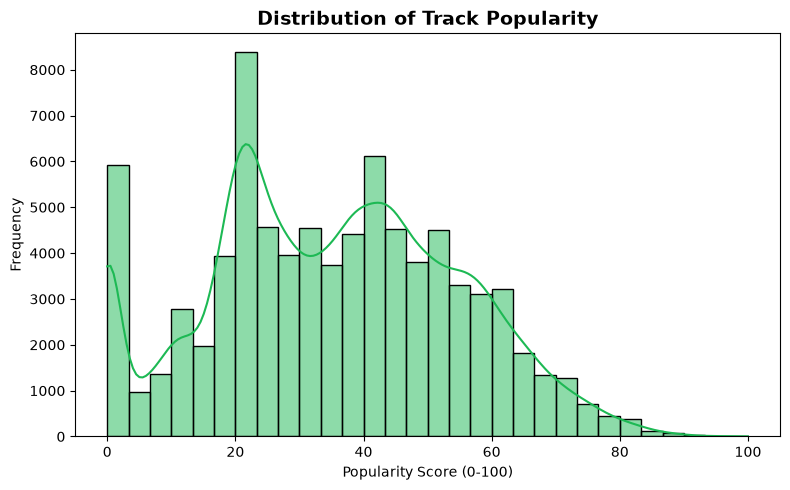

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18876\1874924272.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_lift, x='lift_factor', y='clean_genre', palette='mako')


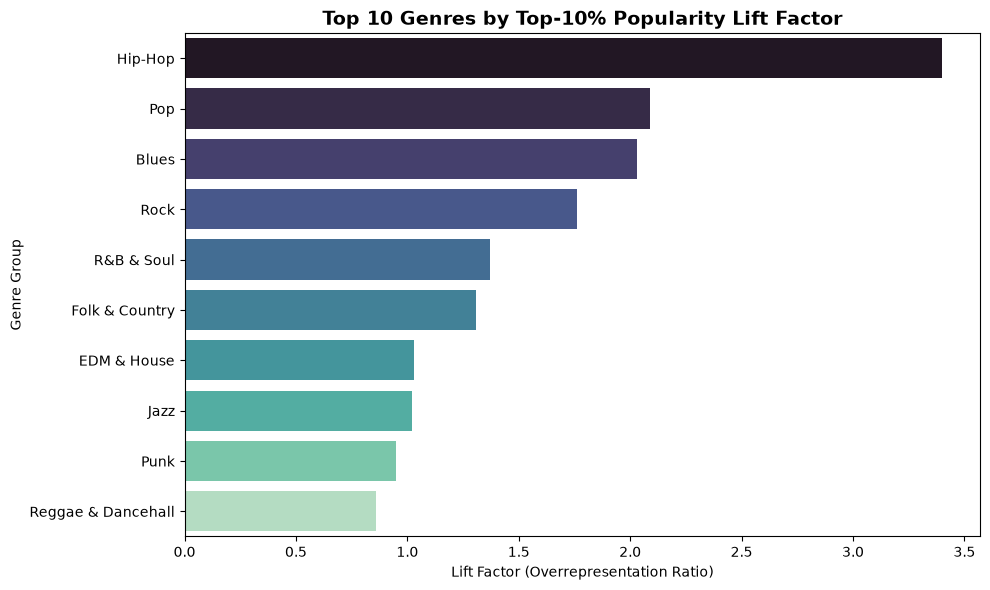

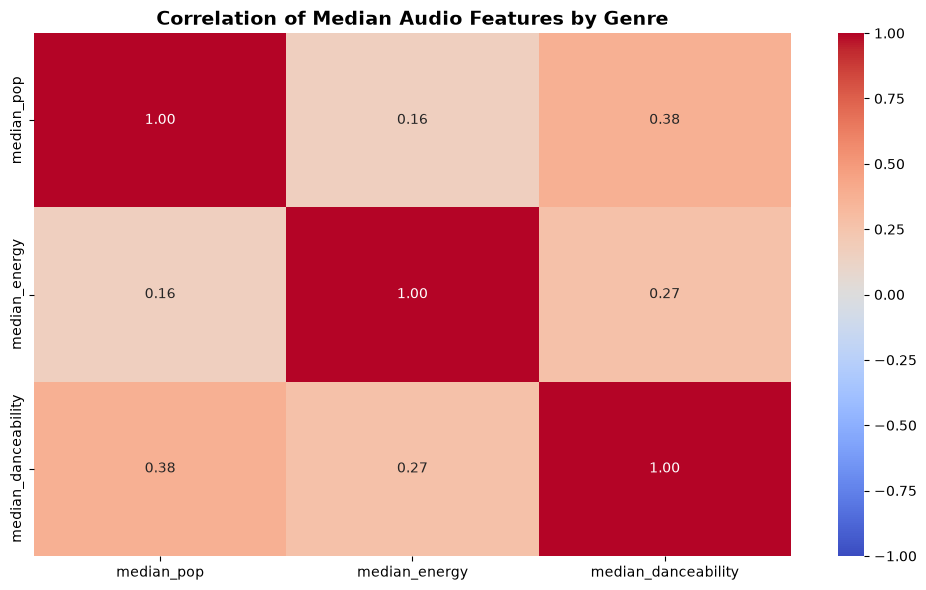

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
total_tracks = len(df_exploded)
p90_threshold = df_exploded['popularity'].quantile(0.90)
df_top10 = df_exploded[df_exploded['popularity'] >= p90_threshold]

baseline_share = df_exploded['clean_genre'].value_counts() / total_tracks
top10_share = df_top10['clean_genre'].value_counts() / len(df_top10)

genre_analysis = df_exploded.groupby('clean_genre').agg(
    total_tracks=('popularity', 'count'),
    unique_artists=('artists', 'nunique'),
    median_pop=('popularity', 'median'),
    median_energy=('energy', 'median'),
    median_danceability=('danceability', 'median')
)

genre_analysis['baseline_share'] = baseline_share
genre_analysis['top10_share'] = top10_share.fillna(0)
genre_analysis['lift_factor'] = (genre_analysis['top10_share'] / genre_analysis['baseline_share']).round(2)

reliable_analysis = genre_analysis[genre_analysis['total_tracks'] >= 200].sort_values(by='lift_factor', ascending=False)

print("=== TOP 10 HIGH-PERFORMING GENRES BY LIFT FACTOR ===")
print(reliable_analysis[['total_tracks', 'unique_artists', 'median_pop', 'lift_factor']].head(10))


plt.figure(figsize=(8, 5))
sns.histplot(df_clean['popularity'], kde=True, bins=30, color='#1DB954')
plt.title("Distribution of Track Popularity", fontsize=14, fontweight='bold')
plt.xlabel("Popularity Score (0-100)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("popularity_distribution.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
top10_lift = reliable_analysis.head(10).reset_index()
sns.barplot(data=top10_lift, x='lift_factor', y='clean_genre', palette='mako')
plt.title("Top 10 Genres by Top-10% Popularity Lift Factor", fontsize=14, fontweight='bold')
plt.xlabel("Lift Factor (Overrepresentation Ratio)")
plt.ylabel("Genre Group")
plt.tight_layout()
plt.savefig("top_genres_lift.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(reliable_analysis[['median_pop', 'median_energy', 'median_danceability']].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title ("Correlation of Median Audio Features by Genre", fontsize=14, fontweight='bold')
plt.tight_layout()              
plt.show()